In [ ]:
from LunaTrace import *
import matplotlib.pyplot as plt

In [8]:
df = makeDF("2026-11-11T12:00:00Z", "2027-11-11T12:00:00Z")

In [9]:
lat, long = -89.67, 129.78
df = calcRVect(lat, long, df)

In [10]:
Spts = df[['SX', 'SY', 'SZ']].to_numpy()
Epts = df[['EX', 'EY', 'EZ']].to_numpy()

df['SCritTheta'] = getCritAngle(-89.67, 129.78, Spts, elevation_grid, dem_transform)
df['ECritTheta'] = getCritAngle(-89.67, 129.78, Epts, elevation_grid, dem_transform)

In [11]:
df.head()

,datetime_utc,iso_utc_str,et,SX,SY,SZ,EX,EY,EZ,STheta,ETheta,SCritTheta,ECritTheta
0,2026-11-11 12:00:00+00:00,2026-11-11T12:00:00Z,8.476705e+08,-1.360644e+08,5.746467e+07,-4.002919e+06,400647.517211,13681.071816,43870.327055,1.844920,-6.692372,20.098165,21.737097
1,2026-11-11 14:00:00+00:00,2026-11-11T14:00:00Z,8.476777e+08,-1.350231e+08,5.986955e+07,-4.003709e+06,400853.859612,13033.402988,43631.219868,1.847872,-6.656110,20.040541,21.734853
2,2026-11-11 16:00:00+00:00,2026-11-11T16:00:00Z,8.476849e+08,-1.339394e+08,6.225556e+07,-4.004473e+06,401056.059090,12377.555740,43378.215698,1.850719,-6.617975,20.006985,21.732634
3,2026-11-11 18:00:00+00:00,2026-11-11T18:00:00Z,8.476921e+08,-1.328136e+08,6.462196e+07,-4.005211e+06,401253.927147,11713.636907,43111.411085,1.853462,-6.577982,20.018798,21.720717
4,2026-11-11 20:00:00+00:00,2026-11-11T20:00:00Z,8.476993e+08,-1.316462e+08,6.696800e+07,-4.005925e+06,401447.273783,11041.760716,42830.906283,1.856099,-6.536148,19.999375,21.717982


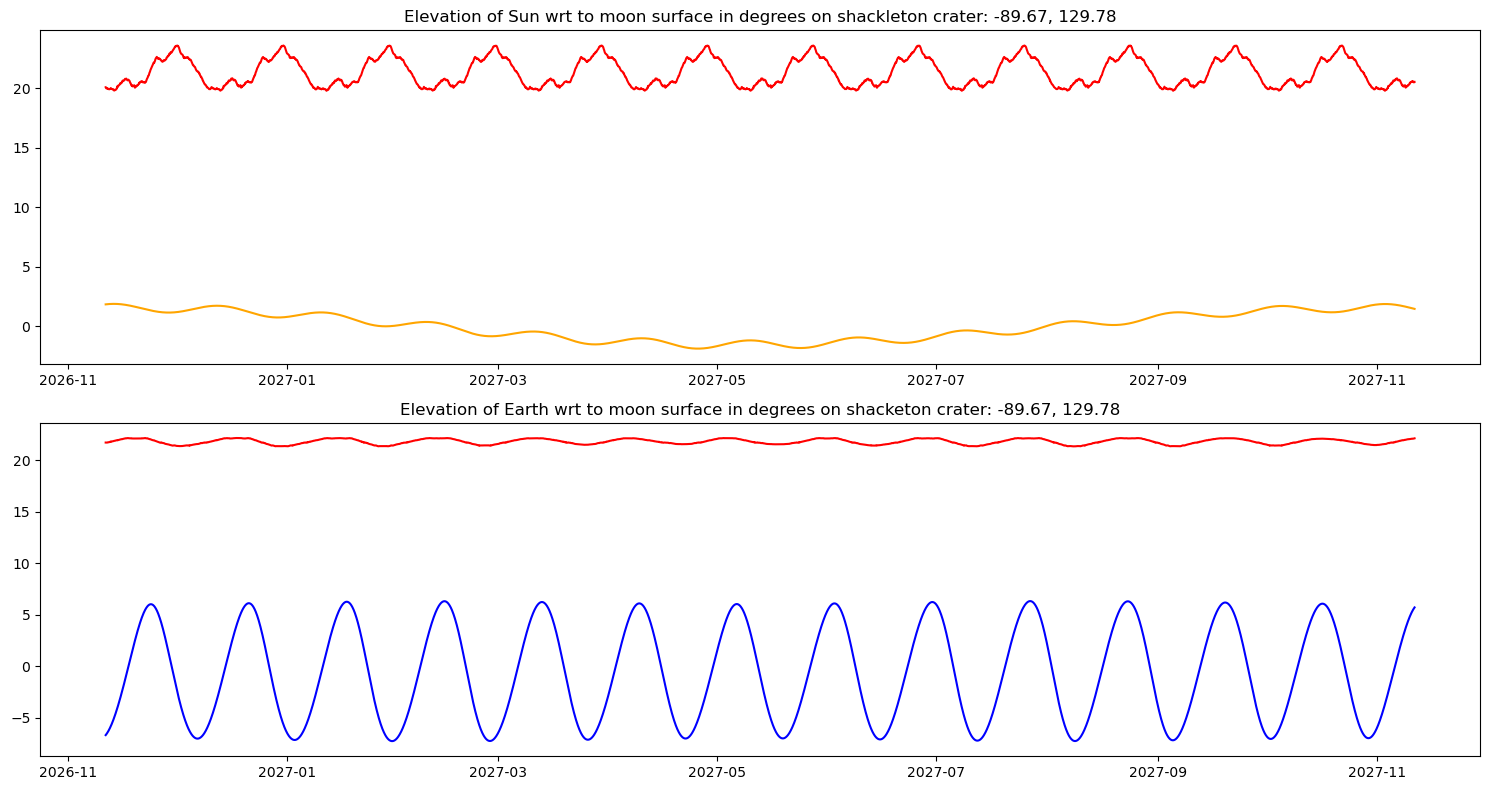

In [14]:
fig, axs = plt.subplots(2, 1, figsize = (15, 8))

axs[0].plot(df['datetime_utc'], df['STheta'], color='orange')
axs[0].plot(df['datetime_utc'], df['SCritTheta'], color='red', linestyle='-')
axs[0].set_title("Elevation of Sun wrt to moon surface in degrees on shackleton crater: {}, {}".format(lat, long))

axs[1].plot(df['datetime_utc'], df['ETheta'], color='blue')
axs[1].plot(df['datetime_utc'], df['ECritTheta'], color='red', linestyle='-')
axs[1].set_title("Elevation of Earth wrt to moon surface in degrees on shacketon crater: {}, {}".format(lat, long))

plt.tight_layout()
plt.show()